# 28 — A Deep Baseline Under the Null

The standing objection to this project is *"only Random Forest"*. The standing
answer — notebooks 22 and 23 — is that with eleven units the permutation null
reaches 74 %, so no architecture can be ranked. Both are arguments. This is the
measurement.

One standard 1D-CNN — **WDCNN** (Zhang, Peng, Li, Chen & Zhang 2017), the
wide-first-kernel network that is the default deep baseline in bearing diagnosis
— is put through exactly the tests the forest was put through, on exactly the
same units, scored exactly the same way:

* **the exact permutation null** (nb22): every OR/IR labelling of the eleven
  units that preserves the class counts — C(11,3) = 165 on XJTU-SY,
  C(11,5) = 462 on Paderborn — each scored bearing-held-out;
* **the deliberately-incapable control** (nb20/22): the same network fed crops
  whose samples are shuffled in time, which keeps every amplitude statistic and
  destroys every waveform;
* **the bearing-identity fingerprint** (nb21): can the network tell six
  nominally identical healthy Paderborn bearings apart, run-held-out, against
  16.7 % chance.

The result was pre-registered as *pass either way*: if the network clears the
null that is noted; if it fingerprints bearings or sits inside the null, that is
the headline.

What keeps this fair to both sides is stated up front. **No early stopping and
no validation set** — a fixed budget of 144 optimiser steps, because stopping on
the held-out unit is notebook 05's leakage in a different coat. **Paired
seeds** — the weight initialisation and the crop draws depend on the fold, not
on the labelling, so the true labelling and every permuted one start from the
same weights and see the same crops. **Per-crop standardisation**, so the
network sees waveform shape and not gain. **Both rigs decimated to WDCNN's
native ~12–16 kHz**, so a 2 048-sample crop spans several shaft revolutions
rather than a fraction of one. And **the forest's own numbers were recomputed
under this notebook's splits** wherever a comparison is drawn, so nothing is
quoted across protocols.

Built by `src/build_raw_windows.py` (the cache), `src/build_cnn_null.py` (every
CNN result) and `src/build_envelope_orders.py` (the spectrum probe).

In [1]:
import json
import pathlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUT = pathlib.Path("../data/processed")
RIGS = [("xjtu", "XJTU-SY", 11), ("pu", "Paderborn", 11)]
S = pd.read_csv(OUT / "cnn_summary.csv")
NULL = {r: pd.read_csv(OUT / f"cnn_null_{r}.csv") for r, _, _ in RIGS}
NB22 = pd.read_csv(OUT / "permutation_nulls.csv")          # the forest's nulls
FIT = {r: pd.read_csv(OUT / f"cnn_trainfit_{r}.csv") for r, _, _ in RIGS}
PROBE = pd.read_csv(OUT / "speccnn_probe.csv")

def per(row):
    return json.loads(row["per_unit"]) if isinstance(row["per_unit"], str) and row["per_unit"] else {}

def pick(rig, model, budget=None):
    s = S[(S.rig == rig) & (S.model == model)]
    if budget is not None:
        s = s[s.budget == budget]
    return s.iloc[0]

C_BLUE, C_ORANGE = "#2a78d6", "#eb6834"
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": INK, "axes.titlecolor": INK, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": BASE,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "legend.frameon": False,
})
FCOLOR = {"OR": C_BLUE, "IR": C_ORANGE}

for r, name, _ in RIGS:
    print(f"{name}: null assignments scored {len(NULL[r])}, true labelling present: "
          f"{bool(NULL[r]['is_true'].any())}")

# Journal-resolution export of the manuscript figures (paper/figures/).
FIGDIR = pathlib.Path("../paper/figures")
FIGDIR.mkdir(parents=True, exist_ok=True)


def save(fig, name):
    """Vector PDF, a 600-dpi RGB TIFF, and a greyscale proof for the print check.

    The TIFF is flattened onto white: an alpha channel leaves the background to
    whoever converts the file, and transparent can come back black.
    """
    from PIL import Image
    fig.savefig(FIGDIR / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIGDIR / f"{name}.tif", dpi=600, bbox_inches="tight",
                pil_kwargs={"compression": "tiff_lzw"})
    im = Image.open(FIGDIR / f"{name}.tif")
    if im.mode in ("RGBA", "LA", "P"):
        im = im.convert("RGBA")
        flat = Image.new("RGB", im.size, "white")
        flat.paste(im, mask=im.split()[-1])
        im = flat
    im.save(FIGDIR / f"{name}.tif", compression="tiff_lzw", dpi=(600, 600))
    proof = im.convert("L")
    proof.thumbnail((1600, 1600))
    (FIGDIR / "greyscale-proofs").mkdir(exist_ok=True)
    proof.save(FIGDIR / "greyscale-proofs" / f"{name}.png")
    print(f"  saved {name}: vector pdf, {im.size[0]}x{im.size[1]} RGB tif at 600 dpi, "
          f"greyscale proof")


XJTU-SY: null assignments scored 165, true labelling present: True
Paderborn: null assignments scored 462, true labelling present: True


## Does the network learn the race?

Eleven bearing-held-out folds per rig, the true OR/IR labelling, the same units
and the same per-snapshot-then-per-unit scoring as notebook 22. The forest's
per-unit numbers are recomputed here under the identical protocol rather than
quoted.

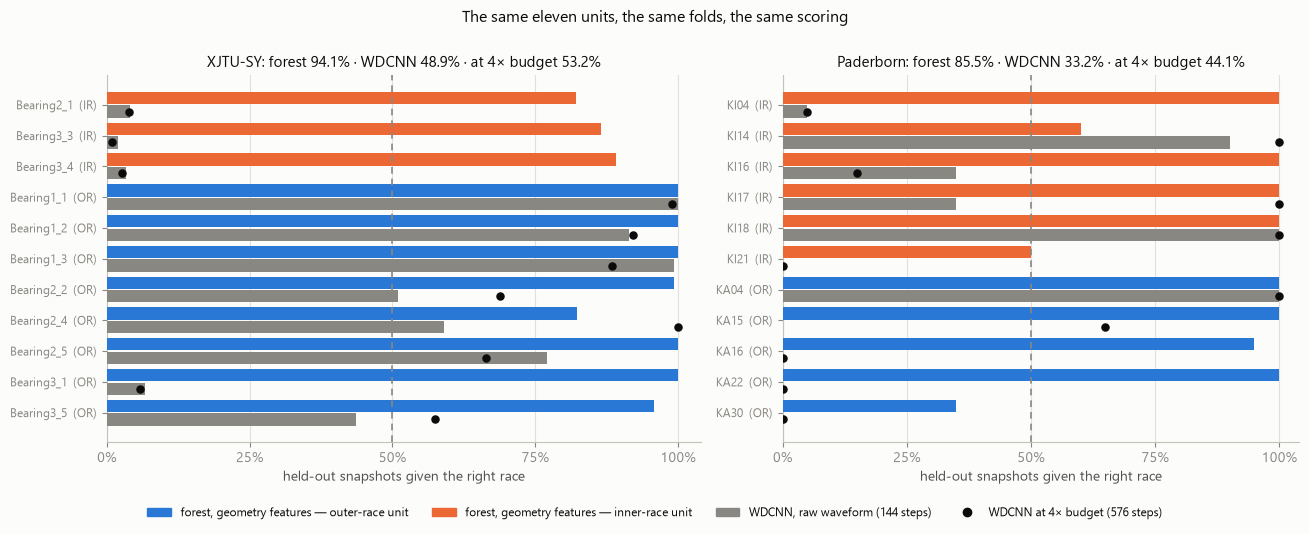

 rig                            model         budget      acc  units_ge_half  n_units
xjtu               WDCNN raw waveform      144 steps 0.488913            6.0       11
xjtu               WDCNN raw waveform 576 steps (4x) 0.532232            7.0       11
xjtu Random Forest, geometry features           nb22 0.941193           11.0       11
  pu               WDCNN raw waveform      144 steps 0.331818            3.0       11
  pu               WDCNN raw waveform 576 steps (4x) 0.440909            5.0       11
  pu Random Forest, geometry features           nb22 0.854545           10.0       11
xjtu       always OR (majority class)    labels only 0.727273            8.0       11
xjtu        condition-majority oracle    labels only 0.545455            6.0       11


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13.2, 5.2), gridspec_kw=dict(width_ratios=[1.15, 1]))
for ax, (r, name, n) in zip(axes, RIGS):
    cnn = per(pick(r, "WDCNN raw waveform", "144 steps"))
    big = per(pick(r, "WDCNN raw waveform", "576 steps (4x)"))
    rf = per(pick(r, "Random Forest, geometry features"))
    truth = {u: ("IR" if u.startswith("KI") or u in ("Bearing2_1", "Bearing3_3", "Bearing3_4") else "OR")
             for u in rf}
    units = sorted(rf, key=lambda u: (truth[u], u))
    y = np.arange(len(units))
    ax.barh(y - 0.22, [100 * rf[u] for u in units], height=0.4, color=[FCOLOR[truth[u]] for u in units],
            zorder=3, label="Random Forest, geometry features")
    ax.barh(y + 0.22, [100 * cnn[u] for u in units], height=0.4, color=MUTED, zorder=3,
            label="WDCNN, raw waveform (144 steps)")
    ax.scatter([100 * big[u] for u in units], y + 0.22, s=26, color=INK, zorder=5,
               label="WDCNN at 4× budget (576 steps)")
    ax.axvline(50, color=MUTED, lw=1.2, ls=(0, (4, 3)), zorder=4)
    ax.set_yticks(y, [f"{u}  ({truth[u]})" for u in units], fontsize=8.5)
    ax.invert_yaxis()
    ax.set_xlim(0, 104)
    ax.set_xticks([0, 25, 50, 75, 100], ["0%", "25%", "50%", "75%", "100%"])
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("held-out snapshots given the right race")
    a_rf = pick(r, "Random Forest, geometry features")["acc"]
    a_c = pick(r, "WDCNN raw waveform", "144 steps")["acc"]
    a_b = pick(r, "WDCNN raw waveform", "576 steps (4x)")["acc"]
    ax.set_title(f"{name}: forest {a_rf:.1%} · WDCNN {a_c:.1%} · at 4× budget {a_b:.1%}", fontsize=10.5)
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
fig.legend(handles=[Patch(color=C_BLUE, label="forest, geometry features — outer-race unit"),
                    Patch(color=C_ORANGE, label="forest, geometry features — inner-race unit"),
                    Patch(color=MUTED, label="WDCNN, raw waveform (144 steps)"),
                    Line2D([], [], marker="o", color=INK, lw=0, label="WDCNN at 4× budget (576 steps)")],
           fontsize=8.5, loc="lower center", ncol=4, bbox_to_anchor=(0.5, 0.0), frameon=False)
fig.suptitle("The same eleven units, the same folds, the same scoring", fontsize=11.5, y=1.0)
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

cols = ["rig", "model", "budget", "acc", "units_ge_half", "n_units"]
print(S[S.model.isin(["WDCNN raw waveform", "Random Forest, geometry features",
                      "always OR (majority class)", "condition-majority oracle"])][cols]
      .to_string(index=False))

**The network does not learn the race, and more training does not help.**

Under the true labelling WDCNN reaches **48.9 %** on XJTU-SY and **33.2 %** on
Paderborn — chance and below — against the forest's **94.1 %** and **85.5 %**
under the identical folds. At unit level the forest names the race of 11 of 11
and 10 of 11 bearings; the network names 6 and 3.

The obvious rebuttal is that 144 optimiser steps is too few. Quadrupling the
budget moves the numbers to **53.2 %** and **44.1 %** — still below chance on
Paderborn, and on XJTU-SY still below the **72.7 %** that *always answering
"outer race"* scores. It also leaves the same units wrong. On XJTU-SY the 4×
network recovers Bearing3_5 and misses Bearing2_1, 3_1, 3_3 and 3_4 exactly as
before; on Paderborn KA16, KA22, KA30, KI04, KI16 and KI21 are wrong at both
budgets. Whatever the network is doing, it does it consistently, and it is not
diagnosis.

## Is it undertrained, or reading something else?

Two controls, both at the 144-step budget the network failed at. If the budget
is the problem, the network should fail these too.

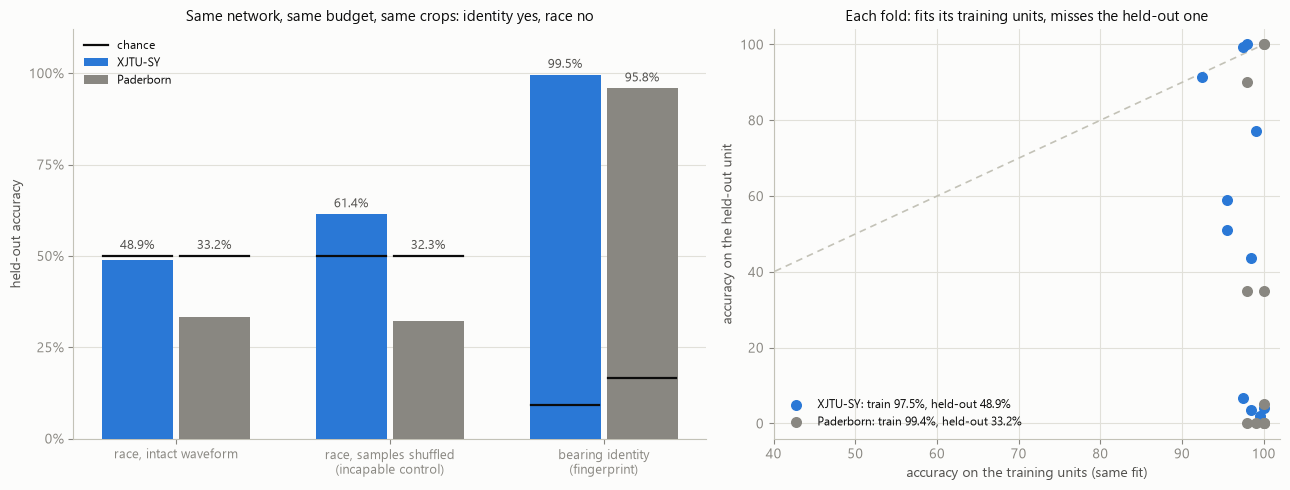

XJTU-SY: training units 97.5% vs held-out unit 48.9% from the same fits; folds at >= 90 % on training units: 11 of 11
XJTU-SY: WDCNN identity 99.5% vs forest 87.3% under the same split (chance 9.1%); shuffled-waveform race control 61.4% vs intact 48.9%
Paderborn: training units 99.4% vs held-out unit 33.2% from the same fits; folds at >= 90 % on training units: 11 of 11
Paderborn: WDCNN identity 95.8% vs forest 95.0% under the same split (chance 16.7%); shuffled-waveform race control 32.3% vs intact 33.2%


In [3]:
fig, (axa, axb) = plt.subplots(1, 2, figsize=(13.0, 5.0), gridspec_kw=dict(width_ratios=[1.25, 1]))

labels = ["race, intact waveform", "race, samples shuffled\n(incapable control)", "bearing identity\n(fingerprint)"]
x = np.arange(len(labels))
for j, (r, name, n) in enumerate(RIGS):
    vals = [pick(r, "WDCNN raw waveform", "144 steps")["acc"],
            pick(r, "WDCNN, samples shuffled in time")["acc"],
            pick(r, "WDCNN bearing-identity fingerprint")["acc"]]
    chance = [0.5, 0.5, 1 / pick(r, "WDCNN bearing-identity fingerprint")["n_units"]]
    bars = axa.bar(x + (j - 0.5) * 0.36, [100 * v for v in vals], width=0.33, zorder=3,
                   color=[C_BLUE, MUTED][j], label=name)
    for xi, v, c in zip(x + (j - 0.5) * 0.36, vals, chance):
        # label above whichever is higher, the bar or its chance line, so the two never collide
        axa.annotate(f"{v:.1%}", (xi, max(100 * v, 100 * c)), xytext=(0, 5), textcoords="offset points",
                     fontsize=9, color=INK2, ha="center")
        axa.plot([xi - 0.16, xi + 0.16], [100 * c] * 2, color=INK, lw=1.6, zorder=5)
axa.plot([], [], color=INK, lw=1.6, label="chance")
axa.set_xticks(x, labels, fontsize=9)
axa.set_ylim(0, 112)
axa.set_yticks([0, 25, 50, 75, 100], ["0%", "25%", "50%", "75%", "100%"])
axa.grid(axis="x", visible=False)
axa.set_ylabel("held-out accuracy")
axa.legend(fontsize=8.5, loc="upper left")
axa.set_title("Same network, same budget, same crops: identity yes, race no", fontsize=10.5)

for j, (r, name, n) in enumerate(RIGS):
    f = FIT[r]
    axb.scatter(100 * f["train_acc"], 100 * f["heldout_acc"], s=48, color=[C_BLUE, MUTED][j],
                zorder=4, label=f"{name}: train {f['train_acc'].mean():.1%}, held-out {f['heldout_acc'].mean():.1%}")
axb.plot([0, 100], [0, 100], color=BASE, lw=1.2, ls=(0, (4, 3)), zorder=2)
axb.set_xlim(40, 102)
axb.set_ylim(-4, 104)
axb.set_xlabel("accuracy on the training units (same fit)")
axb.set_ylabel("accuracy on the held-out unit")
axb.legend(fontsize=8.5, loc="lower left")
axb.set_title("Each fold: fits its training units, misses the held-out one", fontsize=10.5)
plt.tight_layout()
plt.show()

rf_fp = {r: pick(r, "Random Forest bearing-identity fingerprint")["acc"] for r, _, _ in RIGS}
for r, name, n in RIGS:
    f = FIT[r]
    print(f"{name}: training units {f['train_acc'].mean():.1%} vs held-out unit {f['heldout_acc'].mean():.1%} "
          f"from the same fits; folds at >= 90 % on training units: {int((f['train_acc'] >= 0.9).sum())} of {len(f)}")
    fp = pick(r, "WDCNN bearing-identity fingerprint")
    print(f"{name}: WDCNN identity {fp['acc']:.1%} vs forest {rf_fp[r]:.1%} under the same split "
          f"(chance {1 / fp['n_units']:.1%}); shuffled-waveform race control "
          f"{pick(r, 'WDCNN, samples shuffled in time')['acc']:.1%} vs intact "
          f"{pick(r, 'WDCNN raw waveform', '144 steps')['acc']:.1%}")

**It is not undertrained. It is reading the bearing, not the fault.**

With the identical 144-step budget the same network tells the six healthy
Paderborn bearings apart at **95.8 %** (chance 16.7 %) and the eleven XJTU-SY
units apart at **99.5 %** from their early-life snapshots (chance 9.1 %) — as
well as, or better than, the forest on the same windows (95.0 % and 87.3 %). The
budget that cannot find the race finds the individual bearing almost perfectly.

The incapable control says the same thing from the other side. Shuffle every
sample of every crop in time — destroy the waveform, keep only the distribution
of amplitudes — and the network scores **61.4 %** on XJTU-SY and **32.3 %** on
Paderborn, against 48.9 % and 33.2 % intact. The waveform carries no race
information the network uses that the shuffled crop lacks; on XJTU-SY the
shuffled version does better.

The train-versus-held-out numbers close it. Within each fold the network reaches
**97.5 %** and **99.4 %** on the units it was trained on — at least 90 % in all
22 folds — while scoring 48.9 % and 33.2 % on the one it was not. That is the
signature of learning which bearing produced a signal. Notebook 21 predicted it:
both hand-built feature families already fingerprint healthy units at around
90 %, and a model with more capacity was expected to fingerprint harder.

## The exact null

The test the forest passed at p = 0.0061 and p = 0.0043. Every labelling of the
eleven units that preserves the class counts, the identical network, the
identical seeds per fold, the identical scoring, the identical thread count.

  saved fig3_deep_null_both_rigs: vector pdf, 7852x2942 RGB tif at 600 dpi, greyscale proof


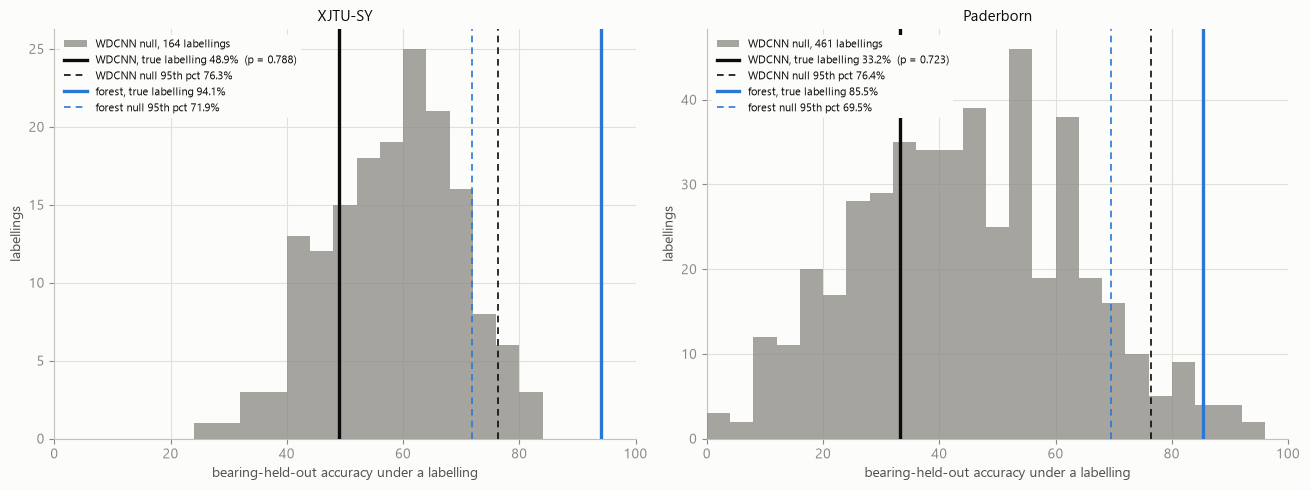

rig             XJTU-SY  Paderborn
n_assign        165.000    462.000
cnn_true          0.489      0.332
cnn_null_mean     0.584      0.448
cnn_null_95       0.763      0.764
cnn_p             0.788      0.723
forest_true       0.941      0.855
forest_null_95    0.719      0.695
forest_p          0.006      0.004


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13.2, 5.0))
res = []
for ax, (r, name, n) in zip(axes, RIGS):
    d = NULL[r]
    t = float(d.loc[d["is_true"], "acc"].iloc[0])
    null = d.loc[~d["is_true"], "acc"].to_numpy()
    p = float((d["acc"] >= t).mean())                     # nb22's exact form, true included
    q95 = float(np.quantile(null, 0.95))
    f22 = NB22[(NB22.rig == name) & (NB22.channel == "geometry")]
    rf_t = float(f22.loc[f22["is_true"], "acc"].iloc[0])
    rf_q95 = float(np.quantile(f22.loc[~f22["is_true"], "acc"], 0.95))
    res.append(dict(rig=name, n_assign=len(d), cnn_true=t, cnn_null_mean=null.mean(),
                    cnn_null_95=q95, cnn_p=p, forest_true=rf_t, forest_null_95=rf_q95,
                    forest_p=float((f22["acc"] >= rf_t).mean())))
    ax.hist(100 * null, bins=np.arange(0, 101, 4), color=MUTED, alpha=0.75, zorder=3,
            label=f"WDCNN null, {len(null)} labellings")
    ax.axvline(100 * t, color=INK, lw=2.4, zorder=5, label=f"WDCNN, true labelling {t:.1%}  (p = {p:.3f})")
    ax.axvline(100 * q95, color=INK, lw=1.2, ls=(0, (4, 3)), zorder=4, label=f"WDCNN null 95th pct {q95:.1%}")
    ax.axvline(100 * rf_t, color=C_BLUE, lw=2.4, zorder=5, label=f"forest, true labelling {rf_t:.1%}")
    ax.axvline(100 * rf_q95, color=C_BLUE, lw=1.2, ls=(0, (4, 3)), zorder=4, label=f"forest null 95th pct {rf_q95:.1%}")
    ax.set_xlim(0, 100)
    ax.set_xlabel("bearing-held-out accuracy under a labelling")
    ax.set_ylabel("labellings")
    # opaque: the true-labelling line runs the full height and would cross the text
    ax.legend(fontsize=8, loc="upper left", frameon=True, facecolor=SURFACE,
              edgecolor="none", framealpha=1.0).set_zorder(6)
    ax.set_title(name, fontsize=10.5)
plt.tight_layout()
save(fig, "fig3_deep_null_both_rigs")
plt.show()
R = pd.DataFrame(res).set_index("rig")
print(R.round(3).T.to_string())

**The network sits inside its null on both rigs, below the middle of it.**

On XJTU-SY the true labelling scores 48.9 % and **130 of 165** labellings score
at least as well, **p = 0.79**. On Paderborn it scores 33.2 % and **334 of
462** do, **p = 0.72**. The forest, on the same labellings and the same units,
reaches 94.1 % at p = 0.0061 and 85.5 % at p = 0.0043. The true labelling falls
below the median of the network's own null on both rigs (59.6 % and 44.5 %).
That is not evidence of doing *worse* than chance — only that it does no better.

Two properties of the null matter beyond this notebook.

**The null is model-specific.** The network's 95th percentiles are **76.3 %**
and **76.4 %**, against the forest's 71.9 % and 69.5 % on the same labellings.
A higher-capacity model finds more ways to fit an arbitrary grouping of eleven
units, so the bar it must clear is higher. Borrowing notebook 22's band for a
network would have understated that bar by four to seven points.

The second architecture below qualifies this. The small spectrum-CNN's null 95th
percentile is **73.5 %** on XJTU-SY and **69.1 %** on Paderborn — the narrowest
null measured anywhere in this project, narrower than any forest's. So the width
tracks capacity *and* input, not the deep/classical divide, and a borrowed band
can misstate the bar in either direction.

**A labelling that is not the race can score very high.** The best labelling in
the network's XJTU-SY null reaches **83.0 %**, and it is the 35 Hz / 12 kN
operating point. The best on Paderborn reaches **95.0 %**, grouping KA15, KA30,
KI04, KI16 and KI18. So a **95 % bearing-held-out accuracy on eleven units, from
a standard deep network, is reachable under a labelling that is not the fault
being diagnosed.**

**Corrected by notebook 30 (2026-09-17).** An earlier version of this paragraph
called the Paderborn grouping *"a set with no documented common fault"*, said
what the five share *"is not established"*, and concluded that the labelling had
*"no physical meaning"*. The damage sheets, parsed in notebook 30, answer the
question that version left open. Three of the five carry plastic-deformation
damage, against one of the other six; two of the three bearings with damage
extent ≥ 2 are among them; and across all 462 labellings the network's accuracy
tracks alignment with documented damage extent (ρ = +0.21, p = 4 × 10⁻⁶) while
the forest's tracks race (ρ = +0.33). The labelling is still not the race, which
is all this notebook's argument needs. It is not without meaning: on Paderborn
the network sorts bearings partly by how badly they are damaged, as on XJTU-SY
it sorts them by operating point.

## What it is actually reading

The null says the network carries no race information. It does not say what the
network uses instead. Two checks answer that, and neither reads a signal.

First, for the true labelling: does each held-out call match *the majority race
among the other units at the same operating point*? Second, across all 165
labellings on XJTU-SY: give each labelling an **operating-point purity** — the
average share of a unit's same-condition neighbours that carry the same label.
If the network sorts by speed and load, its accuracy should rise with purity. A
model reading the fault should not care. Paderborn records a single operating
point, so this check exists only on XJTU-SY.

      unit     cond truth oracle cnn_call  cnn_share_right
Bearing1_1 Bearing1    OR     OR       OR             1.00
Bearing1_2 Bearing1    OR     OR       OR             0.91
Bearing1_3 Bearing1    OR     OR       OR             0.99
Bearing2_1 Bearing2    IR     OR       OR             0.04
Bearing2_2 Bearing2    OR     OR       OR             0.51
Bearing2_4 Bearing2    OR     OR       OR             0.59
Bearing2_5 Bearing2    OR     OR       OR             0.77
Bearing3_1 Bearing3    OR     IR       IR             0.07
Bearing3_3 Bearing3    IR     OR       OR             0.02
Bearing3_4 Bearing3    IR     OR       OR             0.03
Bearing3_5 Bearing3    OR     IR       IR             0.44

           model  agrees_with_oracle  agrees_with_truth
WDCNN, 144 steps                  11                  6
WDCNN, 4x budget                  10                  7
 WDCNN, shuffled                  10                  7

oracle accuracy on the truth: 54.5%  (wrong on ['Bearing2_1', 'Bea

  saved fig4_operating_point_alignment: vector pdf, 7497x2821 RGB tif at 600 dpi, greyscale proof


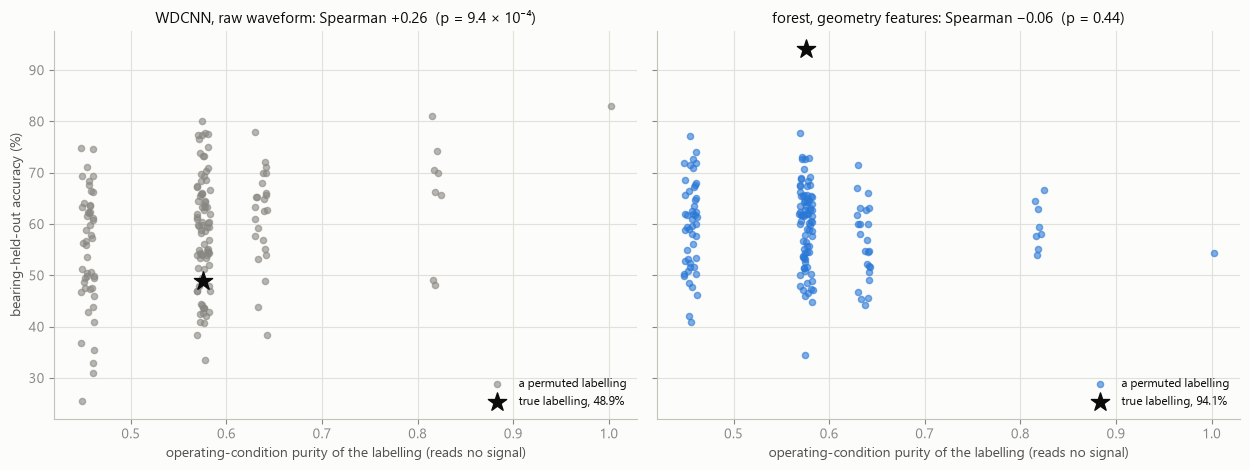

the five labellings the network scores highest:
  83.0%  purity 1.00  IR = 1_1, 1_2, 1_3
  81.0%  purity 0.82  IR = 2_2, 2_4, 2_5
  80.0%  purity 0.58  IR = 2_4, 3_1, 3_3
  78.0%  purity 0.64  IR = 1_1, 1_3, 2_4
  77.7%  purity 0.58  IR = 2_2, 2_5, 3_5

purity of the true labelling 0.576: 57 of 165 labellings are more aligned with the operating conditions
true labelling rank in the WDCNN null: 130 of 165 at or above it


In [5]:
import itertools
from collections import Counter
from scipy.stats import spearmanr

F = {"Bearing1_1": "OR", "Bearing1_2": "OR", "Bearing1_3": "OR", "Bearing2_1": "IR",
     "Bearing2_2": "OR", "Bearing2_4": "OR", "Bearing2_5": "OR", "Bearing3_1": "OR",
     "Bearing3_3": "IR", "Bearing3_4": "IR", "Bearing3_5": "OR"}
UNITS = sorted(F)
COND = {u: u[:8] for u in UNITS}

def oracle(h):
    return Counter(F[o] for o in F if o != h and COND[o] == COND[h]).most_common(1)[0][0]

# 1. the true labelling, unit by unit
rows = []
for tag, src in (("WDCNN, 144 steps", per(pick("xjtu", "WDCNN raw waveform", "144 steps"))),
                 ("WDCNN, 4x budget", per(pick("xjtu", "WDCNN raw waveform", "576 steps (4x)"))),
                 ("WDCNN, shuffled", per(pick("xjtu", "WDCNN, samples shuffled in time")))):
    call = {h: (F[h] if v >= 0.5 else ("IR" if F[h] == "OR" else "OR")) for h, v in src.items()}
    rows.append(dict(model=tag, agrees_with_oracle=sum(call[h] == oracle(h) for h in F),
                     agrees_with_truth=sum(call[h] == F[h] for h in F)))
    if tag == "WDCNN, 144 steps":
        T = pd.DataFrame([dict(unit=h, cond=COND[h], truth=F[h], oracle=oracle(h), cnn_call=call[h],
                               cnn_share_right=round(src[h], 2)) for h in F])
print(T.to_string(index=False))
print()
print(pd.DataFrame(rows).to_string(index=False))
print()
print(f"oracle accuracy on the truth: {np.mean([oracle(h) == F[h] for h in F]):.1%}  "
      f"(wrong on {[h for h in F if oracle(h) != F[h]]})")

# 2. across the whole null
def purity(ir):
    lab = {u: ("IR" if u in ir else "OR") for u in UNITS}
    return float(np.mean([np.mean([lab[o] == lab[h] for o in UNITS if o != h and COND[o] == COND[h]])
                          for h in UNITS]))

cn = NULL["xjtu"].copy()
cn["purity"] = [purity(set(c.split("|"))) for c in cn["combo"]]
COMBOS = list(itertools.combinations(UNITS, 3))           # nb22's enumeration order
fx = NB22[(NB22.rig == "XJTU-SY") & (NB22.channel == "geometry")].reset_index(drop=True)
TRUE_IR = tuple(u for u in UNITS if F[u] == "IR")
assert len(fx) == len(COMBOS) == 165 and bool(fx.loc[COMBOS.index(TRUE_IR), "is_true"])
fx["purity"] = [purity(set(c)) for c in COMBOS]

fig, (axa, axb) = plt.subplots(1, 2, figsize=(12.6, 4.8), sharey=True)
jit = np.random.default_rng(0).uniform(-0.007, 0.007, 165)
for ax, d, name, col in ((axa, cn, "WDCNN, raw waveform", MUTED), (axb, fx, "forest, geometry features", C_BLUE)):
    rho, pr = spearmanr(d["purity"], d["acc"])
    nt = ~d["is_true"].to_numpy()
    ax.scatter(d["purity"].to_numpy()[nt] + jit[:nt.sum()], 100 * d["acc"].to_numpy()[nt], s=20,
               color=col, alpha=0.6, zorder=3, label="a permuted labelling")
    tt = d[d["is_true"]].iloc[0]
    ax.scatter([tt["purity"]], [100 * tt["acc"]], s=190, marker="*", color=INK, zorder=5,
               label=f"true labelling, {tt['acc']:.1%}")
    e = int(np.floor(np.log10(pr)))
    pt = f"{pr:.2f}" if pr >= 0.01 else (f"{pr / 10.0 ** e:.1f} × 10"
                                         + str(e).translate(str.maketrans("-0123456789", "⁻⁰¹²³⁴⁵⁶⁷⁸⁹")))
    ax.set_title(f"{name}: Spearman {rho:+.2f}".replace("-", "−") + f"  (p = {pt})", fontsize=10.5)
    print(f"{name}: accuracy vs operating-condition purity over {len(d)} labellings, "
          f"Spearman {rho:+.2f} (p = {pr:.1e})")
    ax.set_xlabel("operating-condition purity of the labelling (reads no signal)")
    ax.legend(fontsize=8.5, loc="lower right")
axa.set_ylabel("bearing-held-out accuracy (%)")
plt.tight_layout()
save(fig, "fig4_operating_point_alignment")
plt.show()

print("the five labellings the network scores highest:")
for _, r_ in cn.sort_values("acc", ascending=False).head(5).iterrows():
    print(f"  {r_['acc']:.1%}  purity {r_['purity']:.2f}  IR = "
          f"{', '.join(u.replace('Bearing', '') for u in r_['combo'].split('|'))}")
allp = np.array([purity(set(c)) for c in COMBOS])
print()
print(f"purity of the true labelling {purity(set(TRUE_IR)):.3f}: "
      f"{int((allp > purity(set(TRUE_IR))).sum())} of 165 labellings are more aligned with the operating conditions")
print(f"true labelling rank in the WDCNN null: {int((cn['acc'] >= cn.loc[cn['is_true'], 'acc'].iloc[0]).sum())} "
      f"of {len(cn)} at or above it")

**The network's calls follow the operating point.**

For the true labelling, the network's call agrees with the label-only rule —
*whatever race most of the other units at this speed and load have* — on **11 of
11 units** at 144 steps, and on 10 of 11 at 4× budget and under the shuffled
control. The rule reads no signal and is wrong on five units under the true
labels (Bearing2_1, 3_1, 3_3, 3_4 and 3_5). The 144-step network is wrong on
exactly those five.

The null shows this is a property of the network rather than of one labelling.
Across all 165 labellings its accuracy rises with operating-point purity,
**Spearman +0.26 (p = 9 × 10⁻⁴)**, while the forest's does not (−0.06,
p = 0.44). The single labelling the network scores highest, **83.0 %**, is
exactly the 35 Hz / 12 kN operating point: all three of its bearings called
inner race, purity 1.00. The forest reads the fault; the network reads the rig
setting.

Two limits on that reading. The correlation is modest: purity is a coarse proxy
with three groups, and it accounts for part of the null's spread, not all of
it. And the true labelling is not unusually misaligned with operating point —
57 of 165 labellings are more aligned — so the network's failure is not that the
real labels fight the rig setting. It is that a network sorting by rig setting
has nothing else to offer, and on these eleven units that is wrong five times.
Paderborn records one operating point, so there the network has only unit
identity to learn, which is the 95.8 % above.

## Given the physics instead of the waveform

The last objection worth testing: a waveform at three shaft speeds is the wrong
input, and a network given what the forest is given — the envelope spectrum on
a shaft-order axis, floor-relative, with BPFO at 3.08 and BPFI at 4.92 for every
snapshot — would find the race. `src/build_envelope_orders.py` computes that
representation exactly as the feature builders do; a small spectrum-CNN, a
forest on all 576 order bins, and the identity fingerprint are run on it under
the same folds and budget.

One asymmetry has to be closed before the comparison means anything. On
XJTU-SY the forest's nine peaks are **relative to each unit's own first twenty
snapshots** — notebook 22 subtracts that median, which is notebook 13's per-unit
calibration — while the spectrum and the waveform are absolute. So on XJTU-SY
the spectrum models are also run on the same spectra minus each unit's own
healthy reference. Paderborn has no healthy history for a damaged bearing
(notebook 19), and neither side is calibrated there, so that comparison is
already like for like.

 rig                                     model      acc  units_ge_half
xjtu                              spectrum-CNN 0.604428            6.0
xjtu                      RF on 576 order bins 0.586031            7.0
xjtu         spectrum-CNN identity fingerprint 0.727273            NaN
  pu                              spectrum-CNN 0.709091            8.0
  pu                      RF on 576 order bins 0.786364            9.0
  pu         spectrum-CNN identity fingerprint 0.783333            NaN
xjtu         spectrum-CNN, per-unit calibrated 0.624099            8.0
xjtu RF on 576 order bins, per-unit calibrated 0.578957            7.0

XJTU-SY: spectrum-CNN 60.4% (6/11 units) · forest on the same 576 bins 58.6% (7/11) · forest on its 9 physics-selected features 94.1% · spectrum-CNN identity 72.7%
Paderborn: spectrum-CNN 70.9% (8/11 units) · forest on the same 576 bins 78.6% (9/11) · forest on its 7 physics-selected features 85.5% · spectrum-CNN identity 78.3%
XJTU-SY with each unit's own h

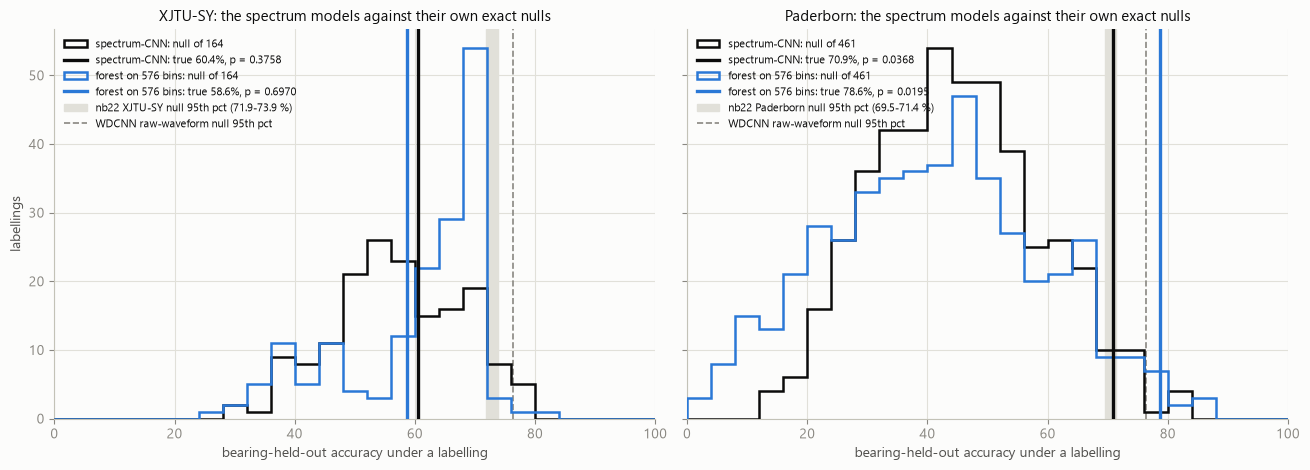

      rig              model   true  null_mean  null_95      p   n null_test
  XJTU-SY       spectrum-CNN 0.6044     0.5719   0.7351 0.3758 165     exact
  XJTU-SY forest on 576 bins 0.5860     0.6039   0.7161 0.6970 165     exact
Paderborn       spectrum-CNN 0.7091     0.4496   0.6909 0.0368 462     exact
Paderborn forest on 576 bins 0.7864     0.4121   0.7136 0.0195 462     exact


In [6]:
cols = ["rig", "model", "acc", "units_ge_half"]
print(PROBE[cols].to_string(index=False))
print()
for r, name, n in RIGS:
    sc = PROBE[(PROBE.rig == r) & (PROBE.model == "spectrum-CNN")].iloc[0]
    rb = PROBE[(PROBE.rig == r) & (PROBE.model == "RF on 576 order bins")].iloc[0]
    fp = PROBE[(PROBE.rig == r) & (PROBE.model == "spectrum-CNN identity fingerprint")].iloc[0]
    print(f"{name}: spectrum-CNN {sc['acc']:.1%} ({int(sc['units_ge_half'])}/11 units) · "
          f"forest on the same 576 bins {rb['acc']:.1%} ({int(rb['units_ge_half'])}/11) · "
          f"forest on its {9 if r == 'xjtu' else 7} physics-selected features "
          f"{pick(r, 'Random Forest, geometry features')['acc']:.1%} · "
          f"spectrum-CNN identity {fp['acc']:.1%}")
cal = PROBE[PROBE.model.str.endswith("per-unit calibrated")]
print("XJTU-SY with each unit's own healthy reference subtracted (as the forest's peaks are): "
      + " · ".join(f"{r_['model'].replace(', per-unit calibrated', '')} {r_['acc']:.1%} "
                   f"({int(r_['units_ge_half'])}/11)" for _, r_ in cal.iterrows()))
# Both rigs now carry an exact spectrum null: every class-preserving labelling, 462 on
# Paderborn and 165 on XJTU-SY, with the true one scored in the same run so its seeds and
# thread count match the null's. p is section 4.2's exact form, #{a(L) >= a(true)} / N,
# which for a complete enumeration equals notebook 24's corrected
# (1 + #{null >= true}) / (1 + N) -- the true labelling is the +1 in the numerator.
fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.8), sharey=True)
spec_null = []
for ax, (r, name, _) in zip(axes, RIGS):
    for key, label, col in (("speccnn", "spectrum-CNN", INK), ("rf", "forest on 576 bins", C_BLUE)):
        path = OUT / f"cnn_null_{r}_orders_{key}.csv"
        if not path.exists():
            continue
        d = pd.read_csv(path)
        if not d["is_true"].any() or (~d["is_true"]).sum() == 0:
            continue                                  # a cache still being filled
        t = float(d.loc[d["is_true"], "acc"].iloc[0])
        null = d.loc[~d["is_true"], "acc"].to_numpy()
        p = float((d["acc"].to_numpy() >= t).mean())
        n_assign = {"xjtu": 165, "pu": 462}[r]
        spec_null.append(dict(rig=name, model=label, true=t, null_mean=null.mean(),
                              null_95=float(np.quantile(null, 0.95)), p=p, n=len(d),
                              null_test="exact" if len(d) == n_assign else f"sampled of {n_assign}"))
        ax.hist(100 * null, bins=np.arange(0, 101, 4), histtype="step", lw=1.8, color=col,
                zorder=3, label=f"{label}: null of {len(null)}")
        ax.axvline(100 * t, color=col, lw=2.4, zorder=5,
                   label=f"{label}: true {t:.1%}, p = {p:.4f}")
    band = NB22[(NB22.rig == name) & ~NB22.is_true].groupby("channel")["acc"].quantile(0.95)
    ax.axvspan(100 * band.min(), 100 * band.max(), color=GRID, zorder=1,
               label=f"nb22 {name} null 95th pct ({100 * band.min():.1f}-{100 * band.max():.1f} %)")
    ax.axvline(100 * NULL[r].loc[~NULL[r].is_true, "acc"].quantile(0.95), color=MUTED, lw=1.2,
               ls="--", zorder=2, label="WDCNN raw-waveform null 95th pct")
    ax.set_xlim(0, 100)
    ax.set_xlabel("bearing-held-out accuracy under a labelling")
    ax.legend(fontsize=8.0, loc="upper left")
    ax.set_title(f"{name}: the spectrum models against their own exact nulls", fontsize=10.5)
axes[0].set_ylabel("labellings")
plt.tight_layout()
plt.show()
print(pd.DataFrame(spec_null).round(4).to_string(index=False))


**Given the physics as input, a network does find the race — on one rig.**

On Paderborn both spectrum models clear their own nulls, now enumerated in full.
The spectrum-CNN reaches **70.9 %** (8 of 11 units) at **p = 0.0368**, and a
forest on the same 576 order bins reaches **78.6 %** (9 of 11) at **p = 0.0195**
— 17 and 9 of the 462 class-preserving labellings respectively. The forest on
seven physics-selected features stays ahead at 85.5 %, p = 0.0043. Both were
sampled at N = 100 in the first version of this notebook, reading 0.0396 and
0.0198; the enumeration moved them very little but replaced an estimate with a
count, which is the only form this project's own argument accepts.

On XJTU-SY neither clears, and that is now measured rather than inferred. The
spectrum-CNN reaches **60.4 %** against a null 95th percentile of 73.5 %,
**p = 0.3758** — 62 of the 165 labellings score at least as well. The forest on
576 bins reaches **58.6 %** against 71.6 %, **p = 0.6970**, beaten by 115 of 165.
With each unit's own healthy reference subtracted — the calibration the forest's
nine peaks carry — they reach **62.4 %** and **57.9 %**, still below every band
measured on this rig. The calibration asymmetry is therefore not what separates
the spectrum from the forest's 94.1 %.

Moving the physics into the input also reduces the fingerprinting, without
removing it: the spectrum-CNN identifies individual bearings at 72.7 % on
XJTU-SY and 78.3 % on Paderborn — still several times chance — against 99.5 %
and 95.8 % for the raw waveform. And one number here is
seed-sensitive. An earlier probe run of the Paderborn forest on 576 bins, with a
single seed for every fold, scored 73.6 %; the 78.6 % above uses the per-fold
seeds the null was run with, and it is the only version with a null.

Read together, the three inputs form a gradient in **how much of the physics is
decided before any learning**:

| input | XJTU-SY | Paderborn |
|---|---|---|
| raw waveform (WDCNN) | 48.9 %, p = 0.788 | 33.2 %, p = 0.723 |
| envelope spectrum on a shaft-order axis (576 bins) | 58.6 % and 60.4 %, p = 0.70 and 0.38 | 70.9 % and 78.6 %, p = 0.0368 and 0.0195 |
| physics-selected features (9 / 7), forest | 94.1 %, p = 0.0061 | 85.5 %, p = 0.0043 |

So at eleven units the architecture is not the variable that matters; the input
is. The raw waveform gives the network the bearing and the operating point, and
it takes those. The order-axis envelope spectrum normalises away shaft speed and
gain, and much of the identity with them; on Paderborn what remains is enough. Only the selected
features carry the race on **both** rigs.

Why the spectrum fails on XJTU-SY is not established. One candidate is the class
balance: XJTU-SY has 3 inner-race units against Paderborn's 6, so leaving one out
trains on two, and notebook 24 showed small minority classes are penalised
hardest. That is a hypothesis this notebook does not test.

### Findings

1. **WDCNN does not learn the race on either rig.** 48.9 % on XJTU-SY and
   33.2 % on Paderborn against the forest's 94.1 % and 85.5 % under identical
   folds; 6 and 3 of 11 units right against 11 and 10. Against its own exact
   null it scores **p = 0.79** and **p = 0.72**; the forest scores p = 0.0061
   and 0.0043 on the same labellings.
2. **It is not undertrained.** At 4× budget it reaches 53.2 % and 44.1 %, with
   the same units wrong, and within every one of 22 folds it scores at least
   90 % on its own training units — 97.5 % and 99.4 % on average.
3. **It reads the bearing, not the fault.** It identifies individual bearings at
   **99.5 %** (XJTU-SY, chance 9.1 %) and **95.8 %** (Paderborn healthy units,
   chance 16.7 %), at or above the forest on the same windows (87.3 %, 95.0 %).
   Shuffling every sample in time leaves race accuracy where it was — 61.4 % and
   32.3 %.
4. **On XJTU-SY its calls follow the operating point.** It agrees with a
   label-only rule — the majority race among other units at the same speed and
   load — on 11 of 11 units, and is wrong on exactly the five units that rule
   gets wrong. Across all 165 labellings its accuracy tracks operating-point
   purity (Spearman **+0.26**, p = 9 × 10⁻⁴) where the forest's does not (−0.06,
   p = 0.44), and its best labelling is the 35 Hz / 12 kN group at 83.0 %.
5. **Nulls belong to the model and its input, and a labelling that is not the
   race can reach 95 %.** WDCNN's null 95th percentiles (76.3 %, 76.4 %) sit
   four to seven points above the forest's, but the small spectrum-CNN's are
   **73.5 %** and **69.1 %** — the narrowest measured anywhere here, narrower
   than any forest's. So the width tracks capacity and input, not the
   deep/classical divide, and a borrowed band can misstate the bar in either
   direction (*revised 2026-09-24, when the second architecture's nulls were
   enumerated; this finding first read "nulls are model-specific" and cited only
   the WDCNN/forest gap*). WDCNN's null maxima are 83.0 % and **95.0 %** — the
   operating point on XJTU-SY and, on Paderborn, a grouping that notebook 30
   found aligned with documented damage extent (*corrected 2026-09-17*; this
   finding first said the grouping had no physical meaning).
6. **At eleven units the input carries the race, not the architecture.** On the
   raw waveform the network finds nothing on either rig. On the envelope spectrum
   along a shaft-order axis, a spectrum-CNN and a forest on the same 576 bins
   clear their nulls on Paderborn — 70.9 % at **p = 0.0368** and 78.6 % at
   **p = 0.0195**, 17 and 9 of all 462 labellings — and fail their own nulls on
   XJTU-SY, 60.4 % at **p = 0.3758** and 58.6 % at **p = 0.6970**, with or without
   per-unit calibration. Only the physics-selected features clear the null on both
   rigs. (*Revised 2026-09-24: all four spectrum nulls are now enumerated in full.
   The two Paderborn p-values were 0.0396 and 0.0198 from 100 sampled labellings,
   and the XJTU-SY pair had no null at all — the finding rested on their sitting
   below every band measured on that rig, which was an inference, not a
   measurement.*)
7. **CPU PyTorch is not bit-stable across thread counts.** The Paderborn true
   labelling moved from 35.9 % to 33.2 % between 3 and 5 threads. Every number
   here was re-run at 5 threads, and everything scored twice agrees exactly.